# Country Socio-Economic Clustering Project

## # Objective:
To categorise the countries using socio-economic and health factors that determine the overall development of the country.

to identify:

* *Development stages (Developed, Developing, Underdeveloped)

* *Country typologies (Service-based, Industrial, Agricultural, Resource-rich)

* *Regional patterns and similarities

## # Expected cluster types:
1. "High-Income Developed"        # High income, high health, low child mortality
2. "Emerging Economies"           # Moderate income, growing, moderate health
3. "Resource-Dependent"           # High exports, moderate income, variable health
4. "Least Developed"              # Low income, high child mortality, low health spend
5. "Transition Economies"         # High inflation, moderate income, improving health

In [68]:
# import 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [69]:
df = pd.read_csv('Country-data.csv')
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


* country	The name of the country.
* child_mort	Child mortality rate – how many children die before age 5. High values mean weaker healthcare.
* exports	How much the country sells goods/services to other countries. High values mean strong global trade.
* health	Total money spent on healthcare. Shows investment in medical services.
* imports	How much the country buys goods/services from other countries. High values mean more dependency on foreign products.
* income	Average income per person. Higher values mean better living standards.
* inflation	Annual rise in prices. High values mean unstable economy.
* life_expec	Average number of years people live. Higher values mean better health and development.
* total_fer	Average number of children born per woman. Shows population growth trends.
* gdpp Economic output per person - Key development metric

# EDA

### Analyse de Forme :
* identify target => not used
* num of ligne & colonne => lignes=167, columns=10
* type des variables(features) => float64(7), int64(2), object(1)
* identifiant Nan (missing values) => no NAN yay :)
* elimine some columns that arent important like:

### Analyse de Forme :
* Visualisation de target => not used
* Comprehension des diff var (seperatly) =>
* Visualisation des relations entre features with target and with each others =>
* Identification des outliers => 

In [70]:
df.shape

(167, 10)

In [71]:
df.dtypes

country        object
child_mort    float64
exports       float64
health        float64
imports       float64
income          int64
inflation     float64
life_expec    float64
total_fer     float64
gdpp            int64
dtype: object

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


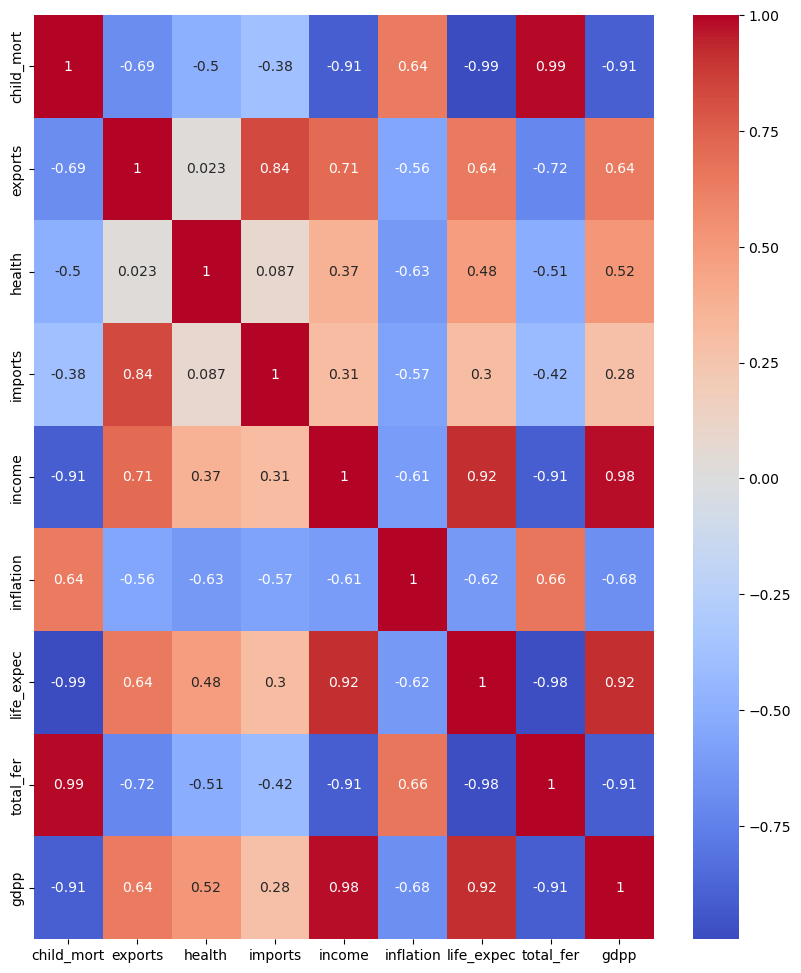

In [73]:
numeric_cols = df.select_dtypes(include=['float64','int64']).columns
corr = df[numeric_cols].corr()
plt.figure(figsize=(10,12))
sns.heatmap(corr.corr(),annot=True,cmap='coolwarm')
plt.show()

In [74]:
df.isna().sum() # no nan

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

In [75]:
df.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


In [76]:
df['country'].value_counts() #normal each contry in each lignes 

country
Afghanistan    1
Morocco        1
Myanmar        1
Namibia        1
Nepal          1
              ..
Georgia        1
Germany        1
Ghana          1
Greece         1
Zambia         1
Name: count, Length: 167, dtype: int64

In [77]:
df.columns

Index(['country', 'child_mort', 'exports', 'health', 'imports', 'income',
       'inflation', 'life_expec', 'total_fer', 'gdpp'],
      dtype='object')

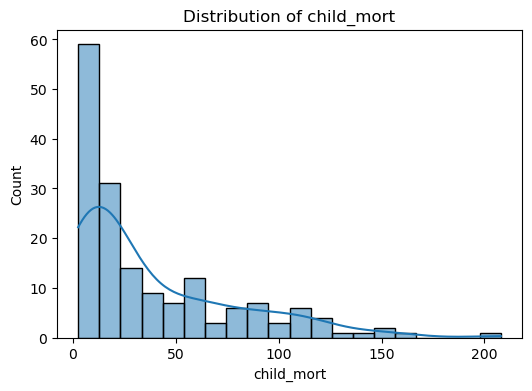

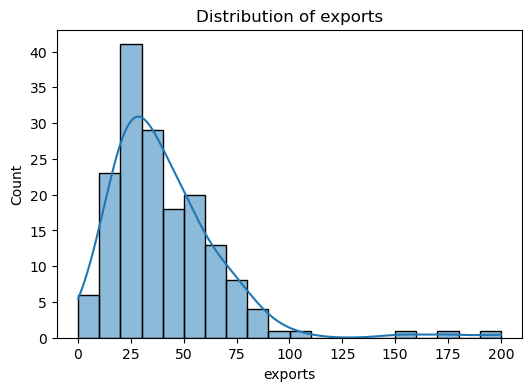

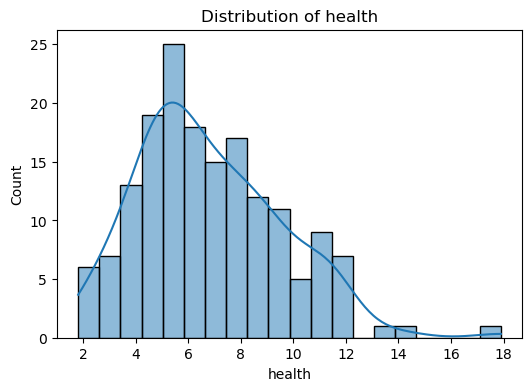

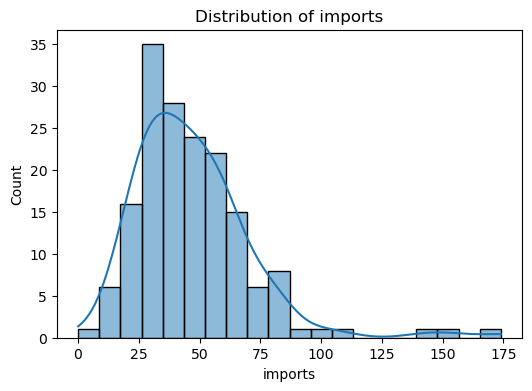

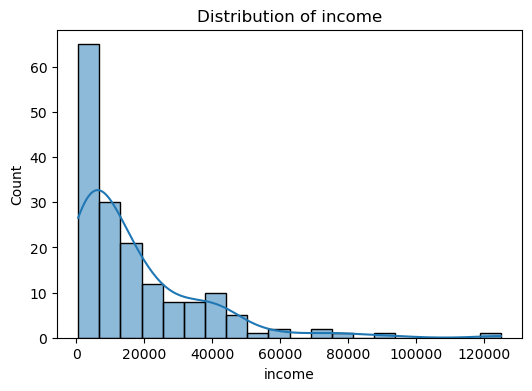

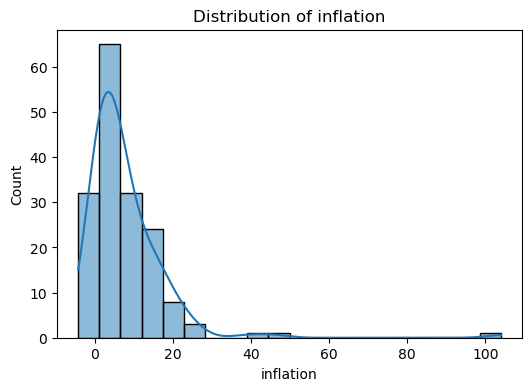

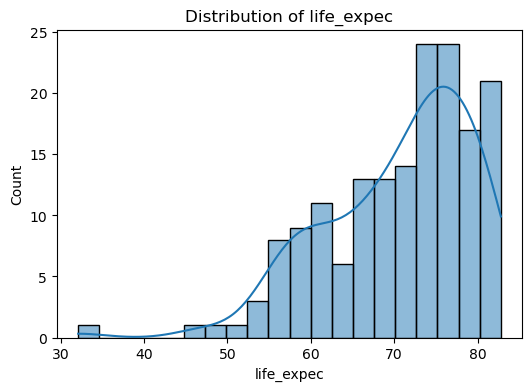

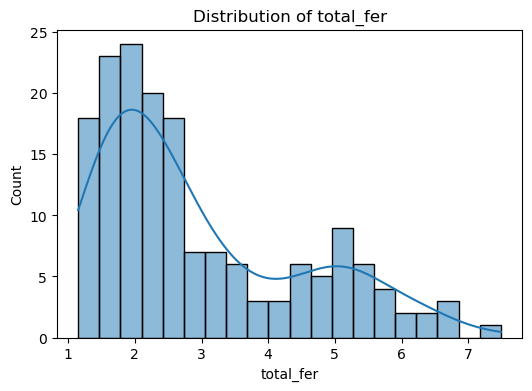

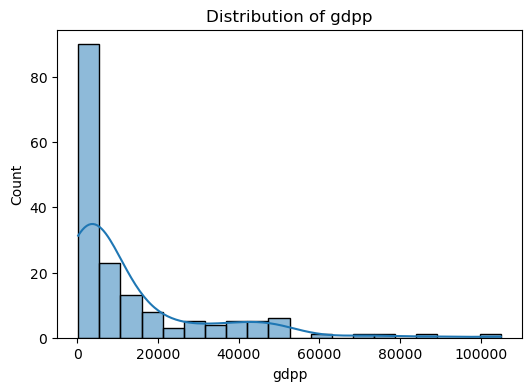

In [78]:
# --- Visualize numerical features ---
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(f"Distribution of {col}")
    plt.show()

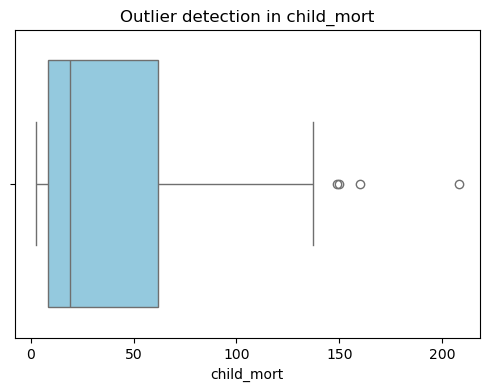

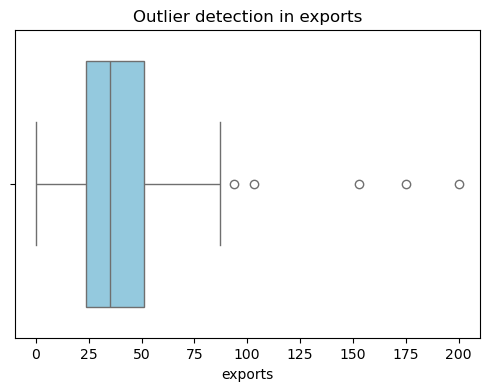

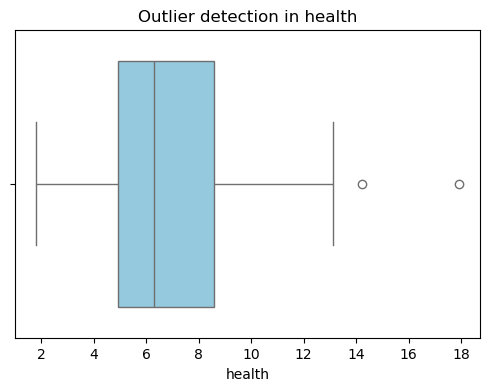

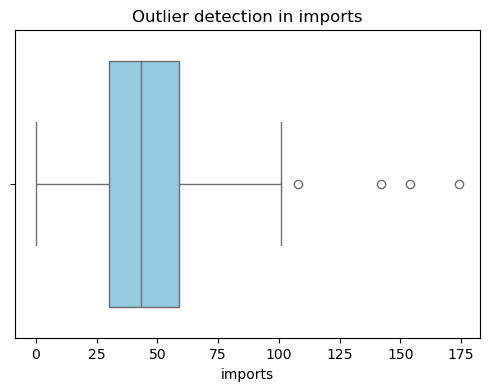

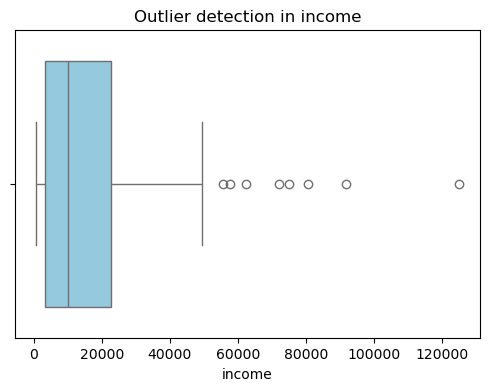

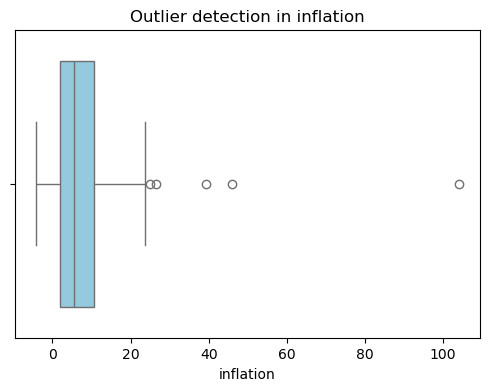

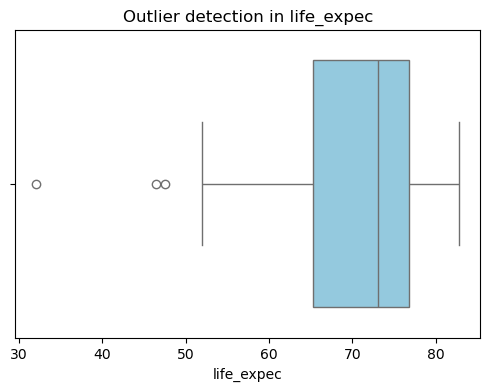

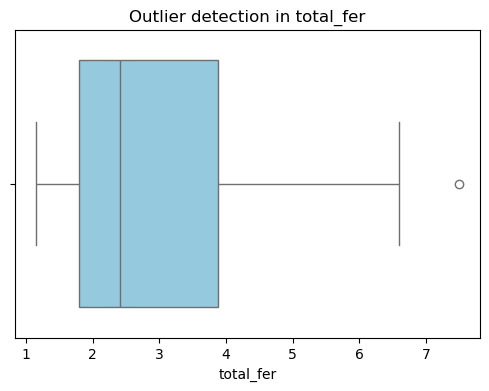

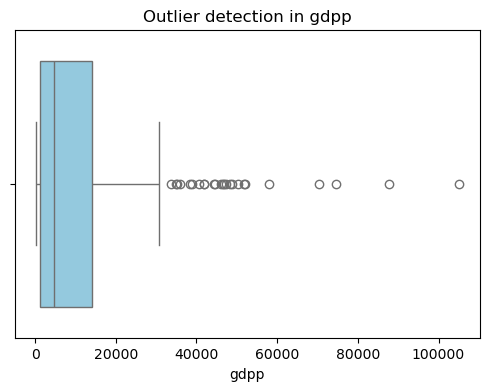

child_mort: 4 outliers
exports: 5 outliers
health: 2 outliers
imports: 4 outliers
income: 8 outliers
inflation: 5 outliers
life_expec: 3 outliers
total_fer: 1 outliers
gdpp: 25 outliers


In [79]:
# outliers 

# Separate numeric and categorical columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

# --- Detect outliers in numeric features using boxplots ---
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col], color="skyblue")
    plt.title(f"Outlier detection in {col}")
    plt.show()

# --- Detect outliers using IQR method ---
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    print(f"{col}: {len(outliers)} outliers")

#### Outliers :
* child_mort: 4 outliers
* exports: 5 outliers
* health: 2 outliers
* imports: 4 outliers
* income: 8 outliers
* inflation: 5 outliers
* life_expec: 3 outliers
* total_fer: 1 outliers
* gdpp: 25 outliers

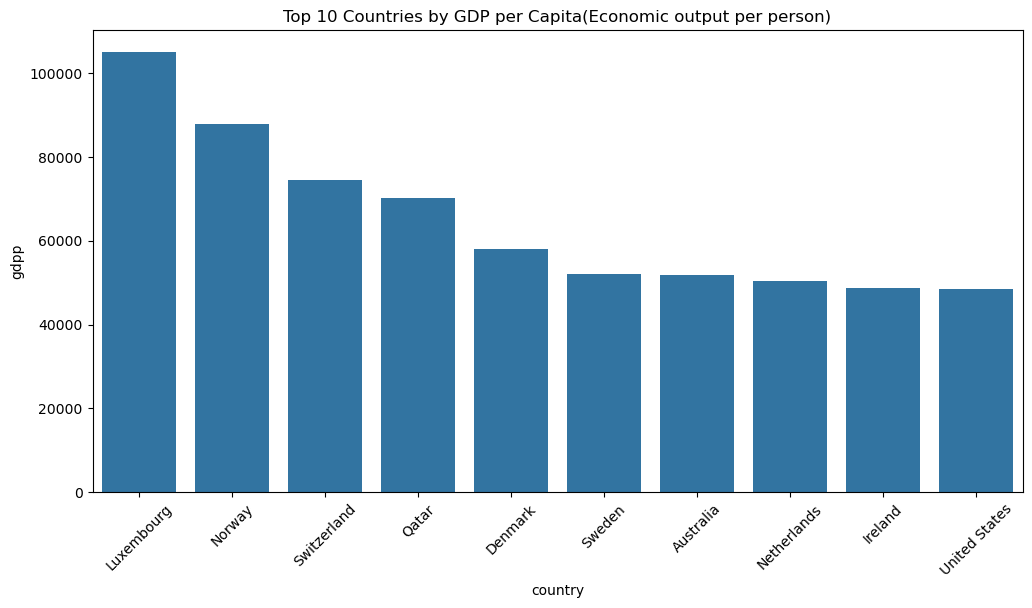

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select top 10 countries by gdpp
top_countries = df.nlargest(10, 'gdpp')

plt.figure(figsize=(12,6))
sns.barplot(x='country', y='gdpp', data=top_countries)
plt.xticks(rotation=45)
plt.title("Top 10 Countries by GDP per Capita(Economic output per person)")
plt.show()
# the top 10 countries with the richest using GDP(Economic output per person) 

## Preprocessing

## Typical Workflow
* Select numeric features (exclude country since it’s just a label).

* Scale/normalize the data (so GDP and child mortality are on the same range).

* Apply clustering algorithm (K-Means is common).

* Interpret clusters using the themes we discussed.

* Label clusters as “High Development,” “Medium Development,” “Low Development” for human understanding.

#### Select numeric features 

In [81]:
df.columns

Index(['country', 'child_mort', 'exports', 'health', 'imports', 'income',
       'inflation', 'life_expec', 'total_fer', 'gdpp'],
      dtype='object')

In [82]:
df=df.drop(['country'],axis=1)
df.head()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


#### Scale/normalize the data (StandardScaler (Z-score normalization))
Best when features are normally distributed or you want to preserve outliers. Common for clustering (K-Means, PCA).

In [83]:
# Log-transform skewed variables
df['gdpp_log'] = np.log1p(df['gdpp'])
df['income_log'] = np.log1p(df['income'])
df['child_mort_log'] = np.log1p(df['child_mort'])

df= df.drop(['gdpp'],axis=1)
df= df.drop(['income'],axis=1)
df= df.drop(['child_mort'],axis=1)

In [84]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled = scaler.fit_transform(df[['gdpp_log','income_log','child_mort_log',
                                  'health','life_expec','exports','imports',
                                  'inflation','total_fer']])


#### Cluster and interpret

In [85]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(scaled)

# Look at average values per cluster
print(df.groupby('cluster').mean())


            exports    health    imports  inflation  life_expec  total_fer  \
cluster                                                                      
0         30.768557  6.059857  44.318084  10.927643   62.104286   4.359857   
1         40.841860  7.443721  42.227907   5.912233   76.516279   1.959070   
2        109.000000  6.715455  99.709091   2.379909   77.736364   1.694545   

          gdpp_log  income_log  child_mort_log  
cluster                                         
0         7.155210    7.989412        4.200763  
1         9.386644    9.858328        2.410329  
2        10.128411   10.475939        1.908165  


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


[0 1 2]


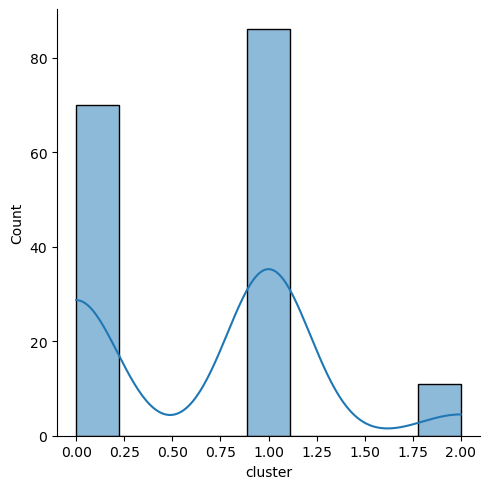

In [86]:
print(df['cluster'].unique()) # we have 3 cluster 
sns.displot(df['cluster'],kde=True) # we can see that cluster 1 mostly repeated after that cluster 0 

In [87]:
#Look at Cluster Averages
# Group by cluster and compute mean of each feature
cluster_summary = df.groupby('cluster').mean()
print(cluster_summary)


            exports    health    imports  inflation  life_expec  total_fer  \
cluster                                                                      
0         30.768557  6.059857  44.318084  10.927643   62.104286   4.359857   
1         40.841860  7.443721  42.227907   5.912233   76.516279   1.959070   
2        109.000000  6.715455  99.709091   2.379909   77.736364   1.694545   

          gdpp_log  income_log  child_mort_log  
cluster                                         
0         7.155210    7.989412        4.200763  
1         9.386644    9.858328        2.410329  
2        10.128411   10.475939        1.908165  


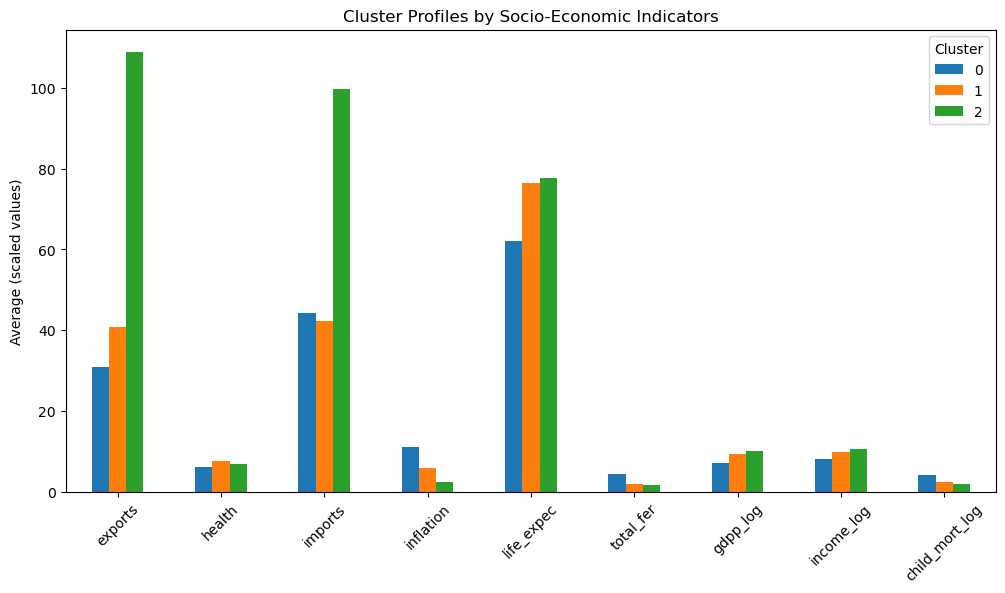

In [88]:
cluster_summary.T.plot(kind='bar', figsize=(12,6))
plt.title("Cluster Profiles by Socio-Economic Indicators")
plt.ylabel("Average (scaled values)")
plt.xticks(rotation=45)
plt.legend(title='Cluster')
plt.show()


### summary:
* cluster 1(had most points):Medium development[Countries with moderate income, moderate healthcare, average life expectancy, moderate fertility rates.]
* cluster 0(the 2nd cluster that have most points):Low development[Countries with low income, weak healthcare, high child mortality, short life expectancy, high fertility rates.]
* cluster 2 (have low points -rare):High development → Countries with high income, high GDP per capita, strong healthcare spending, low child mortality, long life expectancy.

=>the results pretty logic cuz most Countries represent average moderne in terms of heath,lifestyle,income compare to low development and for the High development Countries is kinda rare